# MIE 690A Week 5-6 Project Setup

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week05_06/P0_Project_Setup.ipynb)

Run this notebook before opening a project-track notebook. It checks that your Week-4 data are present, reproduces one simple baseline, and writes a small project configuration file.

## Files

Everything this notebook needs is in the repository: the shared helpers `common/w4utils.py` and `common/w5_common.py` and the fixed reference dataset `data/cavity_data.npz`. The bootstrap cell locates them from a checkout or a Colab clone; no manual upload is required.

You are **not** being asked to rewrite the CFD solver. Your Week-5 task begins from the fixed, quality-checked dataset.

## Assessment contract: public held-out cases are not a new blind experiment
The course has already displayed Re=175, 275 and 375 in earlier lessons, and
some other project test cases have appeared as development/benchmark cases.
Keeping a case out of fitting is necessary, but does not make it unseen to a
student who has inspected it before. Here **public held-out regression test**
is the correct label for reused cases, including older tables labelled "blind".
Those historical labels describe the original author protocol, not a new claim
of student blindness. Do not revise settings using these results and call the
same assessment untouched.

Before final assessment, record a dated manifest containing development cases,
validation case, all candidates/seeds, thresholds, source/data hashes, and an
exposure log (case, earlier lesson, whether viewed). If an instructor provides
new cases, their fields remain withheld until that manifest is frozen. Otherwise
report a reproducible public-case study, **not a new blind generalization study**.
No synthetic replacement test or new CFD qualification is implied by this revision.

<!-- MIE690A enriched learner edition v2 -->

## How to learn from this notebook

This is a guided computational laboratory, not a script to execute without reading. For every numbered stage:

1. read the physical question and write a prediction;
2. inspect the inputs, outputs, units, and split before running code;
3. run the cell and check assertions/warnings;
4. compare with the stated baseline or physical diagnostic; and
5. write one or two sentences explaining what the result does **and does not** establish.

Use **Restart and Run All** before treating any output as final. Hidden state from out-of-order execution is a reproducibility failure.

### Evidence contract

Keep four kinds of evidence separate:

- **numerical evidence:** residuals, accepted cases, data hashes, grid/time/particle budgets;
- **statistical evidence:** losses, relative errors, variability across seeds/cases;
- **physical evidence:** centerlines, walls, divergence, vortex structure, positivity, moments;
- **computational evidence:** runtime, memory, saved configuration, and machine-readable metrics.

A claim is only as strong as the weakest relevant layer.


## What this setup notebook teaches

The setup is itself a scientific exercise. It verifies that every later project starts from the same numerical object rather than from a file that merely has the right name.

You will learn to distinguish:

- **identity:** the SHA-256 hash tells whether two files have identical bytes;
- **integrity:** shape, finite-value, pressure-gauge, and accepted-case checks tell whether the contents satisfy the data contract;
- **numerical quality:** residual and benchmark columns describe how the CFD labels were produced;
- **project validity:** a declared case-wise split defines what future generalization claim is allowed.

### Expected output

At the end you should have a dataset audit table, a recovered Re = 275 interpolation baseline, a plot with physical diagnostics, and `project_choice.json`. Do not begin a project if any assertion fails.


In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week05_06"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

# Repository/Colab bootstrap. Run this before the import cell below.
from pathlib import Path
import sys

def _find_course_root(start=Path.cwd()):
    candidates = [start, *start.parents]
    for base in candidates:
        if (base / "common" / "w5_common.py").exists():
            return base
    # Fallback: helper files placed beside the notebook.
    if (start / "w5_common.py").exists():
        return start
    raise FileNotFoundError(
        "Course root not found. Run this notebook from a FlowMLLab checkout "
        "(the Colab bootstrap cell clones one automatically)."
    )

COURSE_ROOT = _find_course_root()
COMMON_DIR = COURSE_ROOT / "common" if (COURSE_ROOT / "common").exists() else COURSE_ROOT
DATASET_PATH = COURSE_ROOT / "data" / "cavity_data.npz"
if not DATASET_PATH.exists():
    DATASET_PATH = COURSE_ROOT / "cavity_data.npz"
sys.path.insert(0, str(COMMON_DIR))
print("Course root:", COURSE_ROOT)
print("Common helpers:", COMMON_DIR)
print("Dataset:", DATASET_PATH)


Course root: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo
Common helpers: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\common
Dataset: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\data\cavity_data.npz


In [2]:
from pathlib import Path
import json, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import w4utils, w5_common
importlib.reload(w4utils); importlib.reload(w5_common)
print("w4utils:",w4utils.W4_UTILS_VERSION)
print("w5_common:",w5_common.W5_COMMON_VERSION)
print("dataset SHA-256:",w4utils.sha256_file(DATASET_PATH))

data=w5_common.require_week4_files(str(DATASET_PATH))
print("Available Reynolds numbers:",data["Re"])
print("Stored fields:",[k for k in ("u","v","p","psi","omega") if k in data])
print("Field shape:",data["u"].shape)


w4utils: 6.3
w5_common: 1.2
dataset SHA-256: 09b96b744ee4d18126d8dcc92feb60e128774a1b4d41bb3d8c90a63ccfbabc36


Available Reynolds numbers: [100. 150. 175. 200. 225. 250. 275. 300. 350. 375. 400.]
Stored fields: ['u', 'v', 'p', 'psi', 'omega']
Field shape: (11, 65, 65)


## Data schema before the audit

The dataset stores one complete 65×65 field per Reynolds number. Array order is `(case, y, x)`. The primary variables are `u`, `v`, streamfunction `psi`, and vorticity `omega`; pressure is reconstructed and shifted to a zero-mean gauge. The pressure gauge means an arbitrary constant offset is not a prediction error, while a wrong pressure gradient is.

**Prediction prompt:** Which check below would catch a corrupted field full of NaNs? Which would catch a pressure offset? Which would catch convergence to a wrong but finite field? No single check catches all three.


## Dataset audit

The table below confirms which cases were labeled as training and blind test cases in Week 4. Your project may define a new controlled split, but the split must be declared **before** test results are inspected.

In [3]:
audit=pd.DataFrame({
    "Re":data["Re"],"Week4_split":data["split"],
    "accepted":data.get("accepted",np.ones(len(data["Re"]),dtype=bool)),
    "final_residual":data.get("final_residual",np.full(len(data["Re"]),np.nan))
})
display(audit)
assert np.all(np.isfinite(data["u"])) and np.all(np.isfinite(data["v"]))
assert np.allclose(data["p"].mean(axis=(1,2)),0,atol=1e-8)


,Re,Week4_split,accepted,final_residual
0,100.0,train,True,0.000003
1,150.0,train,True,0.000004
2,175.0,test,True,0.000004
3,200.0,train,True,0.000004
4,225.0,train,True,0.000004
5,250.0,train,True,0.000004
6,275.0,test,True,0.000004
7,300.0,train,True,0.000004
8,350.0,train,True,0.000004
9,375.0,test,True,0.000004


## Why interpolation is the recovery baseline

For a smooth one-parameter family, linear field interpolation is cheap, transparent, and often difficult to beat. If `Re_a < Re_* < Re_b`, the baseline is

$$
q(Re_*)=(1-\alpha)q(Re_a)+\alpha q(Re_b),\qquad
\alpha=\frac{Re_*-Re_a}{Re_b-Re_a}.
$$

This operates on complete fields, not randomly selected grid points. It establishes a performance floor for every neural surrogate that uses the same neighboring development cases.

Before running, predict where interpolation error will be largest: the smooth vortex core, the moving-lid corners, or nearly uniform regions. Use the plot to check your reasoning.

## Reproduce a non-neural baseline

This is a recovery check, not your final project. We interpolate the two neighboring Week-4 training fields to predict the development demonstration case at Re=250, withheld only from this local interpolation and compute the same numerical and physical metrics used in Week 4.

The wall metrics used in this project exclude the two moving-lid corners, where the lid and side-wall velocity conditions meet discontinuously. Therefore, the CFD truth should have essentially zero wall error.

,method,Re,relative_L2_uv,MAE_u,MAE_v,p95_vector_error,max_vector_error,div_l2_pred,div_linf_pred,wall_rms_error,wall_max_error,lid_u_mae,centerline_rel_L2_u,centerline_rel_L2_v,centerline_rel_L2_p_vertical,centerline_rel_L2_p_horizontal,relative_L2_p,relative_L2_p_interior,MAE_p,max_p_error
0,field interpolation,250,0.004665,0.000665,0.000415,0.002919,0.004021,6.700236e-16,4.884981e-15,0.0,0.0,0.0,0.00544,0.006749,0.007985,0.01769,0.008924,0.009483,0.000286,0.006623


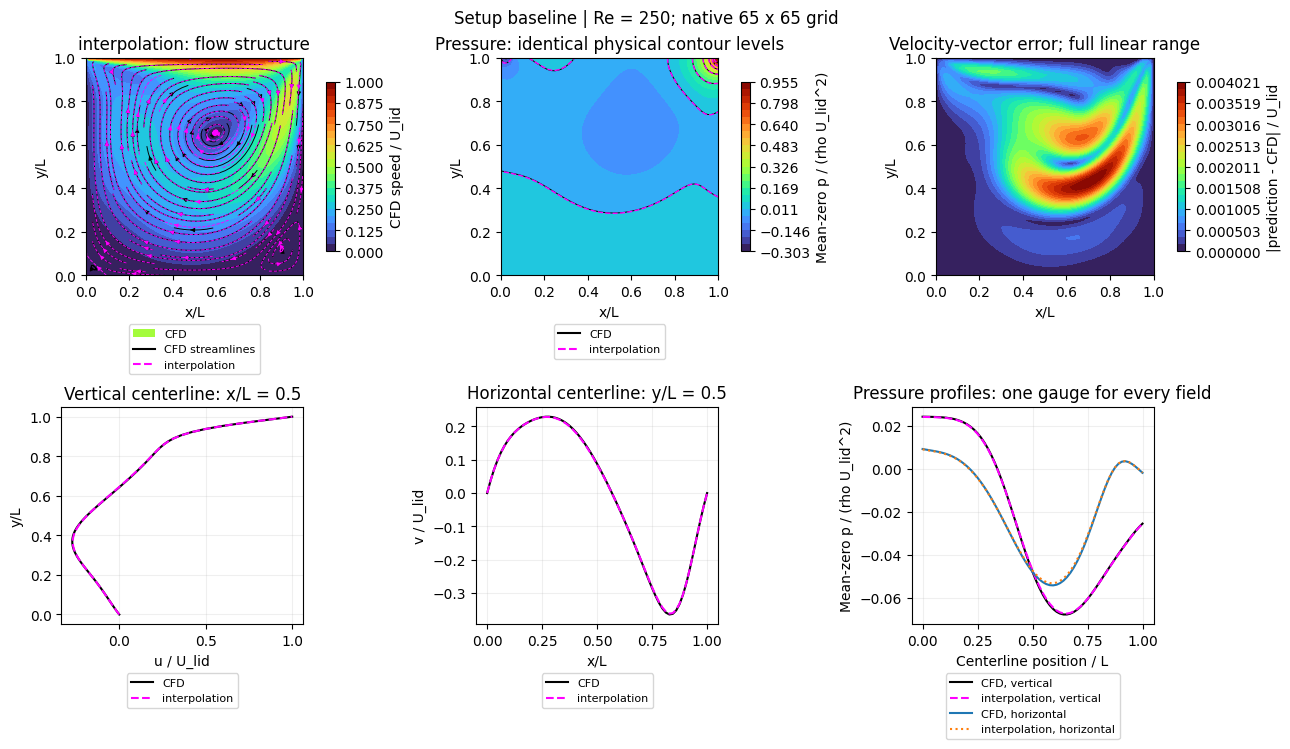

,method,Re,relative_L2_uv,MAE_u,MAE_v,p95_vector_error,max_vector_error,div_l2_pred,div_linf_pred,wall_rms_error,wall_max_error,lid_u_mae,centerline_rel_L2_u,centerline_rel_L2_v,centerline_rel_L2_p_vertical,centerline_rel_L2_p_horizontal,relative_L2_p,relative_L2_p_interior,MAE_p,max_p_error
0,CFD truth reference,250,0.0,0.0,0.0,0.0,0.0,2.093075e-16,3.552714e-15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
train_re=data["Re"][data["split"].astype(str)=="train"]
pred=w5_common.interpolate_case(data,250,train_re[train_re != 250])
report=w5_common.evaluate_prediction(data,250,pred)
display(pd.DataFrame([{"method":"field interpolation","Re":250,**report}]))
fig=w5_common.plot_case_evidence(data,250,{"interpolation":pred},"Setup baseline")
plt.show()
truth_idx=int(np.where(data["Re"]==250)[0][0])
truth=(data["u"][truth_idx],data["v"][truth_idx],data["p"][truth_idx])
truth_report=w5_common.evaluate_prediction(data,250,truth)
display(pd.DataFrame([{"method":"CFD truth reference","Re":250,**truth_report}]))

## From topic to falsifiable question

“Use a neural network for cavity flow” is a topic, not a research question. A usable project question names the baseline, controlled modification, test unit, metric, and possible failure.

Example: *When complete Reynolds-number cases are held out, does a wall-weighted coordinate DNN reduce corner-excluded wall RMS error relative to the same uniformly trained network without increasing global velocity error by more than 10%?*

Write the one-sentence question before choosing plots. A figure should answer the question; the question should not be reverse-engineered from the most attractive output.


## Select exactly one project variant
Choose one of eleven variants: 1A/1B, 2A/2B, 3A/3B, 4A/4B, 5A/5B, or instructor-assigned 6A.
Tracks 1–4 use the cavity archive; Track 5 generates teaching kinetic cases;
Track 6 uses its own FP dataset and GPU workflow. This setup demonstration is
background for Track 6, not a requirement to use cavity_data.npz as its training data.

In [5]:
# EDIT THESE THREE LINES.
STUDENT_NAME = "Your Name"
PROJECT_VARIANT = "1A"   # one of 1A,1B,2A,2B,3A,3B,4A,4B,5A,5B,6A (instructor-assigned)
ONE_SENTENCE_QUESTION = "Replace this with your research question."

assert PROJECT_VARIANT in {"1A","1B","2A","2B","3A","3B","4A","4B","5A","5B","6A"}
card={"student":STUDENT_NAME,"variant":PROJECT_VARIANT,
      "research_question":ONE_SENTENCE_QUESTION,
      "dataset":("Track6_FP_Cavity case manifest" if PROJECT_VARIANT == "6A" else "cavity_data.npz"),"dataset_cases":([] if PROJECT_VARIANT == "6A" else data["Re"].tolist()),
      "case_manifest_pending":PROJECT_VARIANT == "6A"}
w5_common.write_project_card("project_choice.json",card)
print(json.dumps(card,indent=2))

{
  "student": "Your Name",
  "variant": "1A",
  "research_question": "Replace this with your research question.",
  "dataset": "cavity_data.npz",
  "dataset_cases": [
    100.0,
    150.0,
    175.0,
    200.0,
    225.0,
    250.0,
    275.0,
    300.0,
    350.0,
    375.0,
    400.0
  ],
  "case_manifest_pending": false
}


## Submit at the beginning of Week 5

- `project_choice.json`
- one screenshot of the dataset audit
- the interpolation baseline metric table
- your selected project notebook

Do not continue until the baseline runs and you can explain what its error metrics mean.

## Setup concept check

1. Why does a fixed hash not prove that the numerical method is accurate?
2. Why is a random grid-point split easier than a Reynolds-case split?
3. Why is pressure compared after applying a common gauge?
4. If interpolation wins, what scientific conclusion is justified?
5. Which project decision must be frozen before the blind gate?

### Reading

- Ghia, Ghia & Shin (1982) for the cavity centerline benchmark.
- Wilson et al. (2014) and Sandve et al. (2013) for reproducible-computing practice.
- `references/README.md` for the complete annotated route.


## Reproducibility record

Before closing the notebook, record:

- Python and package versions;
- dataset hash and helper versions;
- every physical case in development, validation, and blind sets;
- every seed and candidate value tried;
- the selection rule and when it was frozen;
- output filenames and units; and
- any cell that was skipped, changed, or run with a reduced budget.

Restart the kernel and run all cells in order. If the result changes materially, report the variability instead of selecting the preferred run.

## Troubleshooting without corrupting the experiment

| Symptom | Safe action | Unsafe action |
| --- | --- | --- |
| Missing helper/data file | Re-run the bootstrap and verify paths/hash | Download an unlabeled older copy |
| Training is slow | Use the documented smoke configuration, then label it “smoke” | Quietly reduce epochs/data in the final claim |
| Validation is poor | Inspect scaling, split, and baseline; revise on development data | Open the blind case to choose settings |
| Blind result fails | Report/localize failure and propose a new future experiment | Tune on the blind case while keeping its label “blind” |
| Stochastic result changes | Run multiple declared seeds and report mean/spread | Keep rerunning until one result looks good |
| A neural model loses to interpolation | Verify fairness, then recommend the simpler method | Hide the baseline |

## Final report outline

1. **Question and hypothesis** — one falsifiable sentence.
2. **Data and split** — physical cases, numerical source, and blind unit.
3. **Baseline** — simplest credible comparator using the same allowed information.
4. **Modification** — the one controlled change.
5. **Selection** — validation-only candidates and frozen rule.
6. **Blind numerical result** — aggregate errors and variability.
7. **Physical result** — at least two diagnostics tied to the flow.
8. **Failure or limitation** — where confidence ends.
9. **Cost and reproducibility** — runtime, environment, seeds, saved files.
10. **Conclusion** — helped, hurt, or revealed a tradeoff; no forced positive AI claim.


## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Foundational or supporting notebook; see ARTICLE_FIGURE_MAP.md for its evidence dependency.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).
